In [10]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [11]:
df = pd.read_csv('1-studyhours.csv')

In [12]:
df.head()

,Study Hours,Exam Score
0,3.9,40.0
1,9.6,57.1
2,4.5,42.7
3,11.4,65.1
4,14.4,78.7


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Study Hours  33 non-null     float64
 1   Exam Score   33 non-null     float64
dtypes: float64(2)
memory usage: 660.0 bytes


In [14]:
df.describe()

,Study Hours,Exam Score
count,33.000000,33.000000
mean,15.772727,74.612121
std,7.608723,18.711206
min,3.000000,40.000000
25%,9.600000,58.500000
50%,17.400000,78.800000
75%,21.300000,90.800000
max,30.000000,100.000000


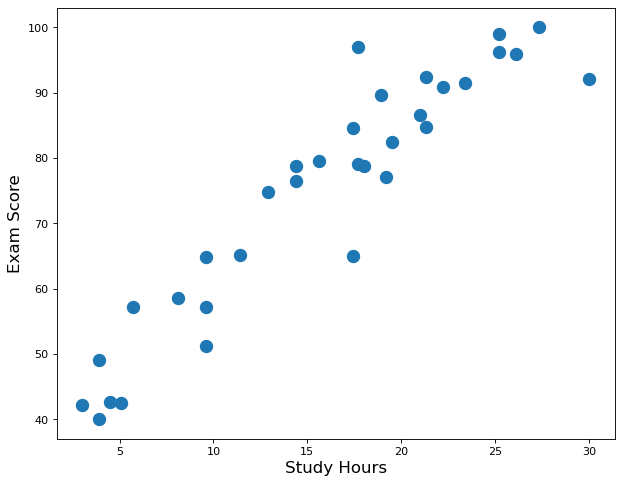

In [15]:
plt.figure(figsize = (9,7), dpi = 80)
plt.scatter(data = df, x = 'Study Hours', y = 'Exam Score', linewidths = 6)
plt.xlabel(df.columns[0], size = 15)
plt.ylabel(df.columns[1], size = 15)
plt.show()

In [16]:
# independent and dependent feauture
# X -> bagimsiz(independent)
# y -> bagimli(dependent)

In [17]:
X = df[['Study Hours']] # ozellikler X i yeni girdilerimizi(bagimsiz(independent)) df(DataFrame) olarak vermemiz gerek.(Sebebi genelde bircok girdinin olmasi)
y = df['Exam Score']

In [18]:
type(X)

pandas.core.frame.DataFrame

In [19]:
type(y)

pandas.core.series.Series

In [20]:
# test - train split

In [21]:
from sklearn.model_selection import train_test_split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42)

In [23]:
y_train

21     58.5
12     92.0
0      40.0
4      78.7
16     57.2
5      78.8
13    100.0
11     95.9
24     51.2
1      57.1
2      42.7
29     82.4
3      65.1
27     79.5
23     42.2
30     91.5
22     76.5
18     64.9
25     42.4
6      77.1
20     49.0
32     89.6
7      90.8
10     92.4
14     86.6
28     79.1
Name: Exam Score, dtype: float64

In [24]:
X_train

,Study Hours
21,8.1
12,30.0
0,3.9
4,14.4
16,5.7
5,18.0
13,27.3
11,26.1
24,9.6
1,9.6


In [25]:
y_test

31    96.2
15    97.0
26    64.8
17    74.7
8     99.0
9     84.6
19    84.7
Name: Exam Score, dtype: float64

In [26]:
X_test

,Study Hours
31,25.2
15,17.7
26,9.6
17,12.9
8,25.2
9,17.4
19,21.3


In [27]:
# Standardize the data set

In [28]:
from sklearn.preprocessing import StandardScaler # neden scaler kullaniriz -> (kolonlar arsindaki buyuk deger farkliliklarini gidermek icin.)

In [29]:
# balanced fauture values
# efficent gradient descent -> gradyan inisinin daha kararli calismasi icin scaler kullanilir.
#l1, l2 -> ceza uyuglanan bir algoritma kullaniyorsak cezalarin duzgun uygulanmasi icin. 

In [30]:
X_train

,Study Hours
21,8.1
12,30.0
0,3.9
4,14.4
16,5.7
5,18.0
13,27.3
11,26.1
24,9.6
1,9.6


In [31]:
Scaler = StandardScaler()

In [32]:
X_train = Scaler.fit_transform(X_train) # modelin testle ilgili birsey bilmemesi gerekir.
X_test = Scaler.transform(X_test) # fit -> data leakage (veri sizintisi) bunu onlemek icin kullanilmaz.

In [33]:
X_train

array([[-0.89166498],
       [ 1.91959769],
       [-1.43081124],
       [-0.08294558],
       [-1.19974856],
       [ 0.37917979],
       [ 1.57300366],
       [ 1.41896187],
       [-0.69911274],
       [-0.69911274],
       [-1.35379035],
       [ 0.57173203],
       [-0.46805005],
       [ 0.07109621],
       [-1.54634258],
       [ 1.07236785],
       [-0.08294558],
       [ 0.3021589 ],
       [-1.27676945],
       [ 0.53322158],
       [-1.43081124],
       [ 0.49471113],
       [ 0.91832606],
       [ 0.80279471],
       [ 0.76428427],
       [ 0.34066934]])

In [34]:
X_test

array([[ 1.30343053],
       [ 0.34066934],
       [-0.69911274],
       [-0.27549782],
       [ 1.30343053],
       [ 0.3021589 ],
       [ 0.80279471]])

In [43]:
from sklearn.linear_model import LinearRegression # n_jobs = -1 -> verirsek butun cpu lari kullanir model yavassa.

In [36]:
regression = LinearRegression()

In [37]:
regression.fit(X_train, y_train)

LinearRegression()

In [77]:
print('Coefficient: ', regression.coef_)
print('Intercept: ', regression.intercept_)

Coefficient:  [16.17860223]
Intercept:  76.9076923076923


In [78]:
# y = 76.91 + 16.18 x

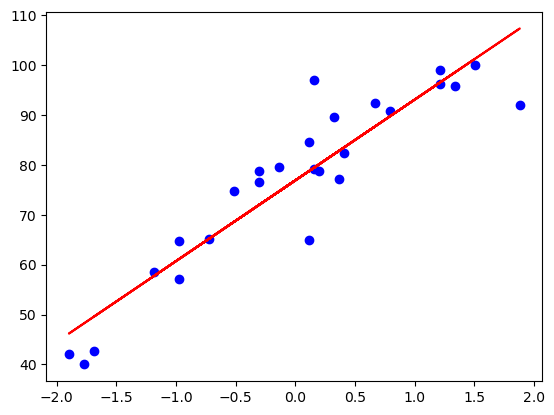

In [85]:
plt.scatter(X_train, y_train, color = 'b', alpha = 1)
plt.plot(X_train, regression.predict(X_train), 'r')
plt.show()

In [86]:
# x = 20 , y = ?

In [87]:
regression.predict([[20]])

array([400.47973694])

In [88]:
Scaler.transform([[20]])

/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([[0.48200796]])

In [89]:
regression.predict(Scaler.transform([[20]]))

/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([84.70590731])

In [139]:
regression.predict(Scaler.transform([[26.75115685]]))

/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([99.9999999])

In [140]:
# prediction with test data 

In [143]:
y_pred_test = regression.predict(X_test)

In [144]:
y_test

25    42.4
14    86.6
30    91.5
16    57.2
24    51.2
20    49.0
19    84.7
Name: Exam Score, dtype: float64

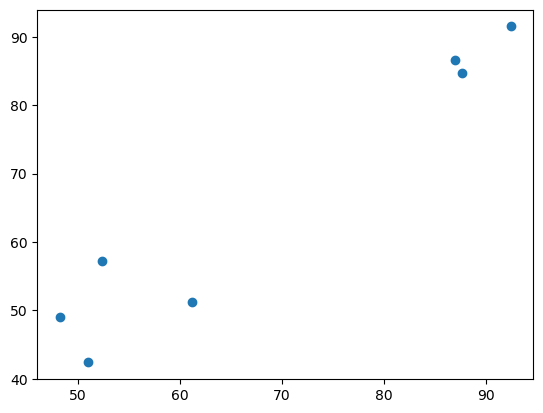

In [145]:
plt.scatter(y_pred_test, y_test)
plt.show()

In [162]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [163]:
mse = mean_squared_error(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
print('mse: ', mse)
print('mae: ', mae)
print('rmse: ', rmse)

mse:  29.45839048833392
mae:  4.054868128856142
rmse:  5.427558427906043


In [165]:
def adjusted_r2_score(r2, y_test, X_test):
    return 1 - (1-r2)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)

In [164]:
r2 = r2_score(y_test, y_pred_test)
print('r2_score: ', r2)

r2_score:  0.9196596206825491


In [170]:
adjusted_r2 = adjusted_r2_score(r2, y_test, X_test)
print('adjusted_r2_score: ', adjusted_r2)

adjusted_r2_score:  0.903591544819059
